# Student early-warning system — OULAD

**Goal:** after the first **8 weeks** of a course, predict which students are likely to **fail or withdraw**,
so tutors can contact them while there is still time to help.

Dataset: [Open University Learning Analytics Dataset (OULAD)](https://analyse.kmi.open.ac.uk/open_dataset)
(CC BY 4.0) — 32,593 enrolments in 7 modules and 4 presentations (2013B, 2013J, 2014B, 2014J), with demographics,
daily clicks in the virtual learning environment (VLE), assessment submissions and the final result.

`prepare_data.py` aggregates the 10M-row click log into weekly totals (`data/*.csv`).
`features.py` contains the feature engineering shared with `train.py` and `predict.py`.

Contents:
1. Data overview and target
2. EDA: activity over time, categorical and numerical features, feature importance
3. Validation strategy (temporal split)
4. Models: logistic regression, decision tree, random forest, XGBoost — with tuning
5. Model selection, threshold and how early we can predict
6. Final model on the test presentation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, mutual_info_score, precision_recall_curve, roc_curve
import xgboost as xgb

from features import CATEGORICAL, CUTOFF_WEEK, build_raw_records, compute_features, load_tables

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

## 1. Data overview

In [2]:
students, assessments, submissions = load_tables("data")
print(students.shape, assessments.shape, submissions.shape)
students.head()

(32593, 56) (182, 6) (168953, 8)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,date_registration,date_unregistration,module_presentation_length,final_result,clicks_before_start,clicks_w0,clicks_w1,clicks_w2,clicks_w3,clicks_w4,clicks_w5,clicks_w6,clicks_w7,clicks_w8,clicks_w9,clicks_w10,clicks_w11,clicks_w12,clicks_w13,clicks_w14,clicks_w15,clicks_w16,clicks_w17,clicks_w18,clicks_w19,days_w0,days_w1,days_w2,days_w3,days_w4,days_w5,days_w6,days_w7,days_w8,days_w9,days_w10,days_w11,days_w12,days_w13,days_w14,days_w15,days_w16,days_w17,days_w18,days_w19
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,-159.0,NaN,268,Pass,98,183,20,100,0,26,60,22,20,0,16,9,31,2,5,27,9,0,27,55,0,4,1,2,0,3,2,2,3,0,1,1,2,1,1,1,1,0,1,2,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,-53.0,NaN,268,Pass,215,175,66,37,57,75,0,21,23,31,25,27,10,59,39,14,22,0,28,24,39,5,2,1,3,4,0,1,3,2,2,2,1,3,4,2,3,0,2,2,2
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,-92.0,12.0,268,Withdrawn,102,107,72,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,-52.0,NaN,268,Pass,169,22,154,108,25,88,119,53,66,12,119,18,0,39,65,99,45,56,38,87,36,1,6,5,4,6,5,3,5,1,4,3,0,3,5,4,5,4,2,4,2
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,-176.0,NaN,268,Pass,295,61,116,37,58,18,16,0,0,4,3,18,50,8,38,0,25,0,31,18,26,5,4,3,4,1,1,0,0,2,1,2,2,2,2,0,3,0,4,2,3


In [3]:
students.isnull().sum()[lambda s: s > 0]

date_registration         45
date_unregistration    22521
dtype: int64

- `imd_band` (deprivation index of the student's area) is missing for ~3% of students, coded as `"?"` in the
  original files → category `unknown`. (The band `10-20` lacks the `%` sign in the source; it is kept as is.)
- `date_registration` is missing for a few students → 0.
- `date_unregistration` is only set for students who withdrew; it is **not** used as a feature (it is the outcome),
  only to drop students who had already left before the cut-off.

In [4]:
students[["num_of_prev_attempts", "studied_credits", "date_registration",
          "module_presentation_length", "clicks_before_start"]].describe().round(1)

,num_of_prev_attempts,studied_credits,date_registration,module_presentation_length,clicks_before_start
count,32593.0,32593.0,32548.0,32593.0,32593.0
mean,0.2,79.8,-69.4,256.0,65.9
std,0.5,41.1,49.3,13.2,129.3
min,0.0,30.0,-322.0,234.0,0.0
25%,0.0,60.0,-100.0,241.0,0.0
50%,0.0,60.0,-57.0,262.0,19.0
75%,0.0,120.0,-29.0,268.0,76.0
max,6.0,655.0,167.0,269.0,3731.0


### Target: final result

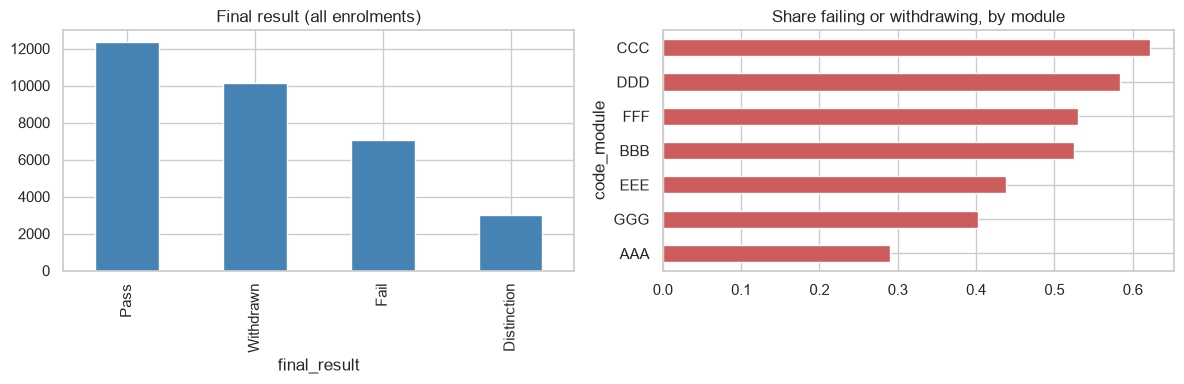

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
students.final_result.value_counts().plot.bar(ax=axes[0], color="steelblue", title="Final result (all enrolments)")
(students.assign(at_risk=students.final_result.isin(["Fail", "Withdrawn"]))
    .groupby("code_module").at_risk.mean().sort_values()
    .plot.barh(ax=axes[1], color="indianred", title="Share failing or withdrawing, by module"))
plt.tight_layout()

We define the target **at_risk = 1** if the final result is `Fail` or `Withdrawn`, and 0 for `Pass` / `Distinction`.
More than half of all enrolments end in failure or withdrawal, and the rate differs a lot between modules —
the module itself will be an informative feature.

### Building the dataset at the cut-off week

In [6]:
records, y, meta = build_raw_records(students, assessments, submissions, cutoff_week=CUTOFF_WEEK)
X = [compute_features(r) for r in records]
df = pd.DataFrame(X).assign(at_risk=y, code_presentation=meta.code_presentation, final_result=meta.final_result)
print(f"{len(df)} students still enrolled at week {CUTOFF_WEEK} | at-risk rate: {y.mean():.3f}")
print(f"excluded (already withdrawn before week {CUTOFF_WEEK}): {len(students) - len(df)}")
df.head()

26532 students still enrolled at week 8 | at-risk rate: 0.420
excluded (already withdrawn before week 8): 6061


,code_module,gender,region,highest_education,imd_band,age_band,disability,num_of_prev_attempts,studied_credits,date_registration,clicks_before_start_log,clicks_total_log,clicks_first2_log,clicks_last2_log,active_days,active_weeks,weeks_since_last_activity,clicks_trend,assessments_due,assessments_submitted,assessments_missed,late_submissions,score_mean,score_min,at_risk,code_presentation,final_result
0,AAA,M,East Anglian Region,HE Qualification,90-100%,55<=,N,0,240.0,-159.0,4.595120,6.068426,5.318120,3.761200,17.0,7,0,-0.154225,2,2,0,0,81.5,78.0,0,2013J,Pass
1,AAA,F,Scotland,HE Qualification,20-30%,35-55,N,0,60.0,-53.0,5.375278,6.120297,5.488938,3.806662,19.0,7,0,-0.359021,2,2,0,1,69.0,68.0,0,2013J,Pass
2,AAA,F,South East Region,A Level or Equivalent,50-60%,35-55,N,0,60.0,-52.0,5.135798,6.455199,5.176150,4.787492,35.0,8,0,0.044419,2,2,0,0,71.5,71.0,0,2013J,Pass
3,AAA,F,West Midlands Region,Lower Than A Level,50-60%,0-35,N,0,60.0,-176.0,5.690359,5.726848,5.181784,0.000000,18.0,6,2,-0.669607,2,1,1,1,69.0,69.0,0,2013J,Pass
4,AAA,M,Wales,A Level or Equivalent,80-90%,35-55,N,0,60.0,-110.0,5.627621,6.480045,5.624018,4.682131,37.0,8,0,-0.164962,2,1,1,0,79.0,79.0,0,2013J,Pass


## 2. EDA

### Activity over time

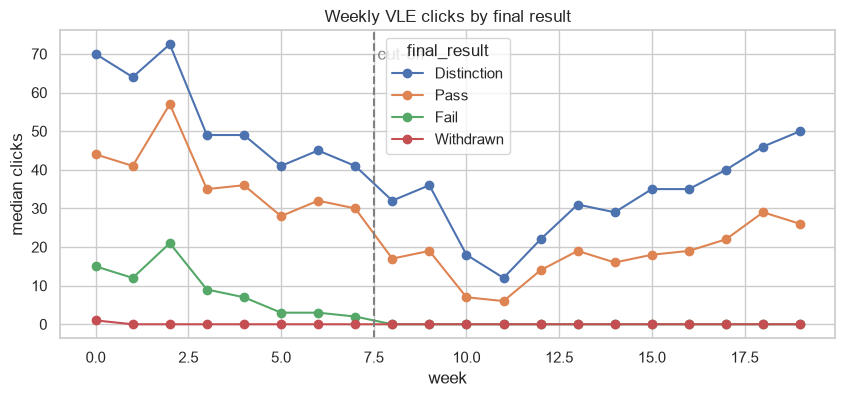

In [7]:
week_cols = [f"clicks_w{w}" for w in range(20)]
curves = (students.assign(final_result=students.final_result)
          .groupby("final_result")[week_cols].median().T)
curves.index = range(20)
ax = curves[["Distinction", "Pass", "Fail", "Withdrawn"]].plot(figsize=(10, 4), marker="o")
ax.axvline(CUTOFF_WEEK - 0.5, color="gray", linestyle="--")
ax.text(CUTOFF_WEEK - 0.4, ax.get_ylim()[1] * 0.9, "cut-off", color="gray")
ax.set(xlabel="week", ylabel="median clicks", title="Weekly VLE clicks by final result")
plt.savefig("images/weekly_clicks.png", dpi=120, bbox_inches="tight")

The curves separate from the very first week: the median student who passes clicks about 3 times more than the
median student who fails, and by week 5 the median failing student has almost stopped using the platform. The
median student who withdraws barely uses it at all. This is the signal the early-warning model exploits.

### Categorical features: risk ratio and mutual information

In [8]:
global_rate = df.at_risk.mean()
for col in ["code_module", "highest_education", "imd_band", "age_band", "disability"]:
    g = df.groupby(col).at_risk.agg(["mean", "count"])
    g["risk_ratio"] = (g["mean"] / global_rate).round(2)
    display(g.sort_values("risk_ratio", ascending=False))

,mean,count,risk_ratio
code_module,,,
CCC,0.482418,3242,1.15
DDD,0.483475,5053,1.15
FFF,0.427944,6377,1.02
BBB,0.399936,6256,0.95
GGG,0.371001,2407,0.88
EEE,0.337349,2490,0.80
AAA,0.248939,707,0.59


,mean,count,risk_ratio
highest_education,,,
No Formal quals,0.581301,246,1.38
Lower Than A Level,0.504026,10307,1.20
A Level or Equivalent,0.373725,11669,0.89
HE Qualification,0.341185,4033,0.81
Post Graduate Qualification,0.259928,277,0.62


,mean,count,risk_ratio
imd_band,,,
0-10%,0.543529,2550,1.29
10-20,0.502017,2727,1.19
20-30%,0.480279,2865,1.14
30-40%,0.424211,2883,1.01
40-50%,0.419219,2612,1.00
50-60%,0.411810,2591,0.98
70-80%,0.386937,2419,0.92
60-70%,0.376860,2420,0.90
80-90%,0.350587,2299,0.83


,mean,count,risk_ratio
age_band,,,
0-35,0.440303,18460,1.05
35-55,0.376189,7887,0.90
55<=,0.281081,185,0.67


,mean,count,risk_ratio
disability,,,
Y,0.514481,2486,1.22
N,0.410380,24046,0.98


In [9]:
mi = pd.Series({c: mutual_info_score(df[c], df.at_risk) for c in CATEGORICAL}).sort_values(ascending=False)
mi.round(4)

highest_education    0.0106
imd_band             0.0099
code_module          0.0063
region               0.0034
age_band             0.0021
disability           0.0019
gender               0.0005
dtype: float64

### Numerical features: AUC as feature importance and correlation

In [10]:
numerical = [c for c in df.columns if c not in CATEGORICAL + ["at_risk", "code_presentation", "final_result"]]
auc = {}
for c in numerical:
    a = roc_auc_score(df.at_risk, df[c])
    auc[c] = max(a, 1 - a)  # direction does not matter for importance
pd.Series(auc).sort_values(ascending=False).round(3)

score_mean                   0.729
score_min                    0.713
clicks_last2_log             0.703
active_days                  0.701
active_weeks                 0.694
clicks_total_log             0.680
clicks_first2_log            0.656
weeks_since_last_activity    0.651
assessments_missed           0.640
assessments_submitted        0.631
clicks_before_start_log      0.630
clicks_trend                 0.571
num_of_prev_attempts         0.544
late_submissions             0.533
studied_credits              0.531
assessments_due              0.529
date_registration            0.510
dtype: float64

Text(0.5, 1.0, 'Correlation matrix')

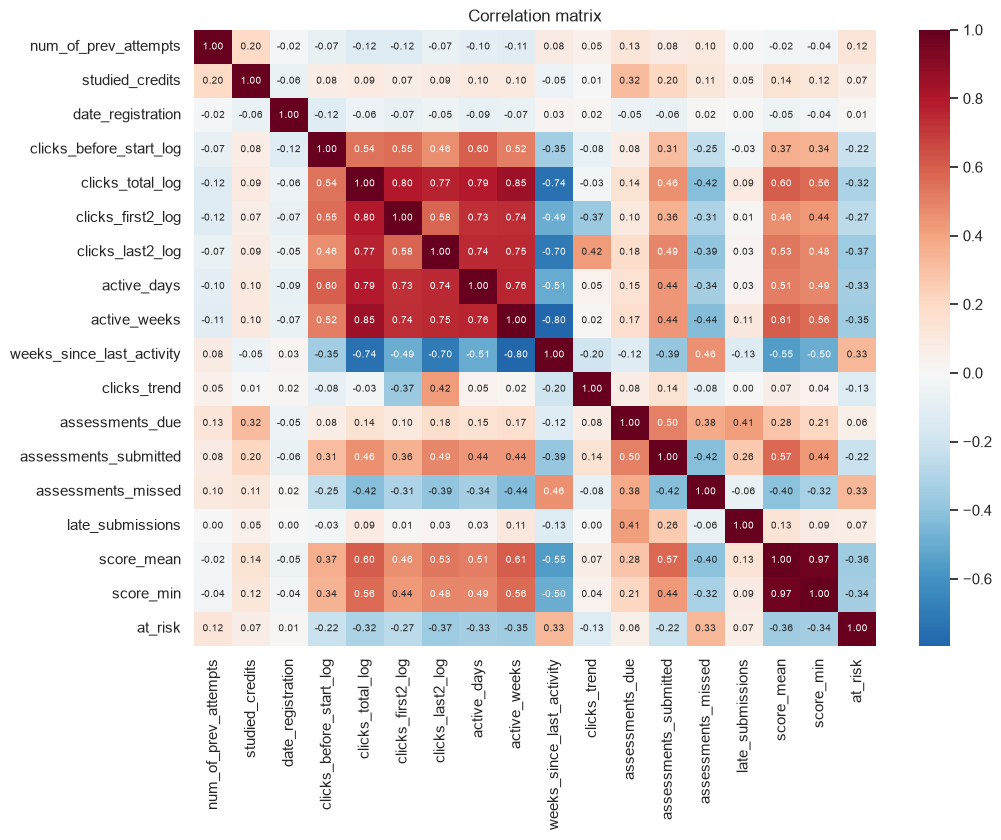

In [11]:
plt.figure(figsize=(11, 8))
sns.heatmap(df[numerical + ["at_risk"]].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Correlation matrix")

- Assessment results (`score_mean`, `score_min`) and recent / regular activity (`clicks_last2_log`,
  `active_days`, `active_weeks`) are the strongest single signals (AUC 0.69-0.73 each).
- Several activity features are strongly correlated with each other (total clicks, active days, active weeks).
  This matters for logistic regression (we scale and regularize), much less for trees.
- Demographics carry some signal (education level and deprivation index have the highest mutual information,
  disability has a risk ratio of 1.22) but much less than behaviour.

## 3. Validation strategy

The model will be used on **future** presentations, so a random split would be optimistic
(students of the same presentation share tutors, materials and calendar). We split by time:

| Split | Presentations | Use |
|---|---|---|
| train | 2013B, 2013J | fit models |
| validation | 2014B | tuning and model selection |
| test | 2014J | final evaluation (once) |

Metric: **ROC AUC** (ranking quality — tutors work through a list sorted by risk).

In [12]:
Xa = np.array(X, dtype=object)
pres = meta.code_presentation.values
tr, va, te = np.isin(pres, ["2013B", "2013J"]), pres == "2014B", pres == "2014J"
X_train, X_val, X_test = list(Xa[tr]), list(Xa[va]), list(Xa[te])
y_train, y_val, y_test = y[tr], y[va], y[te]
print(len(X_train), len(X_val), len(X_test))
print(y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

def val_auc(model):
    model.fit(X_train, y_train)
    return roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])

11434 6217 8881
0.425 0.46 0.386


## 4. Models

### 4.1 Logistic regression (scaled features, tuning C)

In [13]:
lr_scores = {}
for C in [0.001, 0.01, 0.1, 1, 10]:
    model = make_pipeline(DictVectorizer(sparse=False), StandardScaler(),
                          LogisticRegression(C=C, max_iter=2000))
    lr_scores[C] = val_auc(model)
    print(f"C={C:<6} AUC={lr_scores[C]:.4f}")
best_C = max(lr_scores, key=lr_scores.get)

C=0.001  AUC=0.8173


C=0.01   AUC=0.8253


C=0.1    AUC=0.8255


C=1      AUC=0.8254


C=10     AUC=0.8254


### 4.2 Decision tree (max_depth, min_samples_leaf)

max_depth            8.000000
min_samples_leaf    50.000000
auc                  0.800689
Name: 22, dtype: float64

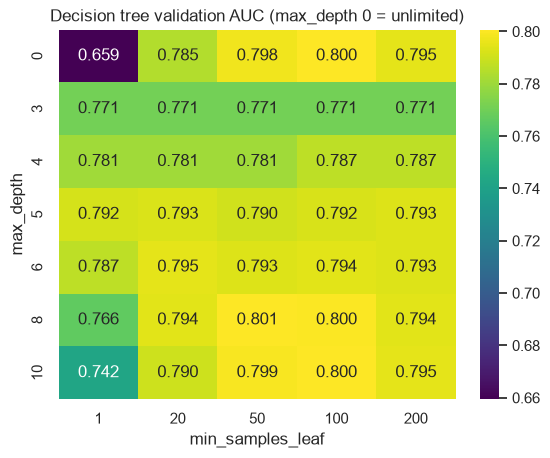

In [14]:
dt_scores = []
for depth in [3, 4, 5, 6, 8, 10, None]:
    for leaf in [1, 20, 50, 100, 200]:
        model = make_pipeline(DictVectorizer(sparse=False),
                              DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1))
        dt_scores.append((depth, leaf, val_auc(model)))
dt_scores = pd.DataFrame(dt_scores, columns=["max_depth", "min_samples_leaf", "auc"])
dt_scores["max_depth"] = dt_scores.max_depth.fillna(0).astype(int)  # 0 = unlimited
sns.heatmap(dt_scores.pivot(index="max_depth", columns="min_samples_leaf", values="auc"),
            annot=True, fmt=".3f", cmap="viridis")
plt.title("Decision tree validation AUC (max_depth 0 = unlimited)")
dt_best = dt_scores.loc[dt_scores.auc.idxmax()]
dt_best

An unlimited tree with leaves of size 1 memorizes the training data (lowest AUC); limiting depth and leaf size fixes it.

### 4.3 Random forest (n_estimators, max_depth, min_samples_leaf)

In [15]:
rf_scores = []
for depth in [8, 12, 16, None]:
    for leaf in [1, 5, 20]:
        model = make_pipeline(DictVectorizer(sparse=False),
                              RandomForestClassifier(n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
                                                     max_features="sqrt", n_jobs=-1, random_state=1))
        rf_scores.append((depth, leaf, val_auc(model)))
rf_scores = pd.DataFrame(rf_scores, columns=["max_depth", "min_samples_leaf", "auc"])
rf_scores["max_depth"] = rf_scores.max_depth.fillna(0).astype(int)
rf_best = rf_scores.loc[rf_scores.auc.idxmax()]
display(rf_scores.pivot(index="max_depth", columns="min_samples_leaf", values="auc").round(4))
rf_best

min_samples_leaf,1,5,20
max_depth,,,
0,0.8107,0.8156,0.8157
8,0.8124,0.8137,0.8136
12,0.8143,0.8168,0.8157
16,0.8133,0.8158,0.8163


max_depth           12.000000
min_samples_leaf     5.000000
auc                  0.816841
Name: 4, dtype: float64

In [16]:
rf_depth = None if rf_best.max_depth == 0 else int(rf_best.max_depth)
for n in [50, 100, 200, 400]:
    model = make_pipeline(DictVectorizer(sparse=False),
                          RandomForestClassifier(n_estimators=n, max_depth=rf_depth,
                                                 min_samples_leaf=int(rf_best.min_samples_leaf),
                                                 n_jobs=-1, random_state=1))
    print(f"n_estimators={n:<4} AUC={val_auc(model):.4f}")

n_estimators=50   AUC=0.8149


n_estimators=100  AUC=0.8165


n_estimators=200  AUC=0.8168


n_estimators=400  AUC=0.8164


### 4.4 XGBoost (eta, max_depth, min_child_weight, number of rounds)

In [17]:
dv = DictVectorizer(sparse=False)
Xtr = dv.fit_transform(X_train); Xva = dv.transform(X_val)
names = [f.replace("=", "_").replace("<", "lt").replace(" ", "_") for f in dv.get_feature_names_out()]
dtrain = xgb.DMatrix(Xtr, label=y_train, feature_names=names)
dval = xgb.DMatrix(Xva, label=y_val, feature_names=names)

def xgb_run(eta, max_depth, min_child_weight, rounds=1000):
    params = {"eta": eta, "max_depth": max_depth, "min_child_weight": min_child_weight,
              "objective": "binary:logistic", "eval_metric": "auc", "subsample": 0.8,
              "colsample_bytree": 0.8, "seed": 1, "nthread": 8}
    booster = xgb.train(params, dtrain, num_boost_round=rounds, evals=[(dval, "val")],
                        early_stopping_rounds=50, verbose_eval=False)
    return booster.best_score, booster.best_iteration + 1

xgb_scores = []
for eta in [0.3, 0.1, 0.05]:
    for depth in [3, 4, 6]:
        for mcw in [1, 10, 30]:
            auc_, rounds = xgb_run(eta, depth, mcw)
            xgb_scores.append((eta, depth, mcw, rounds, auc_))
xgb_scores = pd.DataFrame(xgb_scores, columns=["eta", "max_depth", "min_child_weight", "best_rounds", "auc"])
xgb_best = xgb_scores.loc[xgb_scores.auc.idxmax()]
display(xgb_scores.sort_values("auc", ascending=False).head(8))
xgb_best

,eta,max_depth,min_child_weight,best_rounds,auc
10,0.10,3,10,155,0.825366
23,0.05,4,30,173,0.825325
20,0.05,3,30,222,0.825200
9,0.10,3,1,156,0.825186
19,0.05,3,10,229,0.824955
18,0.05,3,1,229,0.824884
14,0.10,4,30,114,0.824853
11,0.10,3,30,143,0.824389


eta                   0.100000
max_depth             3.000000
min_child_weight     10.000000
best_rounds         155.000000
auc                   0.825366
Name: 10, dtype: float64

Early stopping on the validation presentation picks the number of boosting rounds for each configuration.
Smaller `eta` needs more rounds; shallow trees work best here.

## 5. Model selection

logistic_regression    0.8255
xgboost                0.8254
random_forest          0.8164
decision_tree          0.8007
dtype: float64

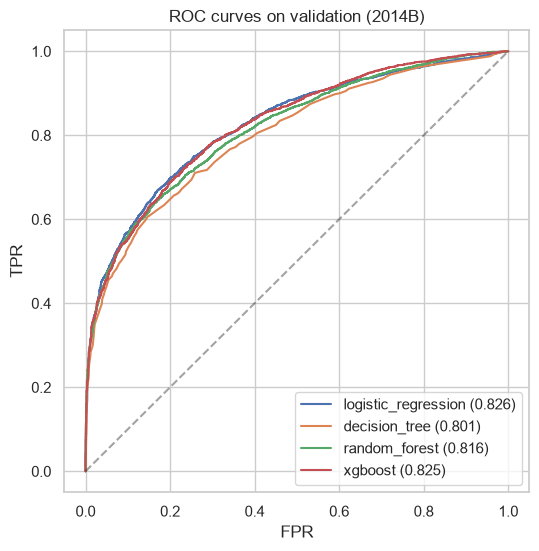

In [18]:
best_models = {
    "logistic_regression": make_pipeline(DictVectorizer(sparse=False), StandardScaler(),
                                         LogisticRegression(C=best_C, max_iter=2000)),
    "decision_tree": make_pipeline(DictVectorizer(sparse=False), DecisionTreeClassifier(
        max_depth=None if dt_best.max_depth == 0 else int(dt_best.max_depth),
        min_samples_leaf=int(dt_best.min_samples_leaf), random_state=1)),
    "random_forest": make_pipeline(DictVectorizer(sparse=False), RandomForestClassifier(
        n_estimators=400, max_depth=rf_depth, min_samples_leaf=int(rf_best.min_samples_leaf),
        n_jobs=-1, random_state=1)),
    "xgboost": make_pipeline(DictVectorizer(sparse=False), xgb.XGBClassifier(
        learning_rate=xgb_best.eta, max_depth=int(xgb_best.max_depth),
        min_child_weight=int(xgb_best.min_child_weight), n_estimators=int(xgb_best.best_rounds),
        subsample=0.8, colsample_bytree=0.8, random_state=1, n_jobs=8)),
}
summary = {}
plt.figure(figsize=(6, 6))
for name, model in best_models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_val)[:, 1]
    summary[name] = roc_auc_score(y_val, p)
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name} ({summary[name]:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC curves on validation (2014B)"); plt.legend()
pd.Series(summary).sort_values(ascending=False).round(4)

Tuned logistic regression and XGBoost are practically tied (difference < 0.001 AUC, well within noise); the
random forest is slightly behind and a single decision tree is clearly worse.

With equal performance we choose **logistic regression** (C=0.1, standardized features): it is simpler,
faster, easier to explain to tutors (each weight has a direction) and less likely to break when the data
changes. Most of the signal is close to linear once counts are log-transformed. `train.py` uses this model.

### Choosing a decision threshold

model=logistic_regression | threshold maximizing F1 = 0.34


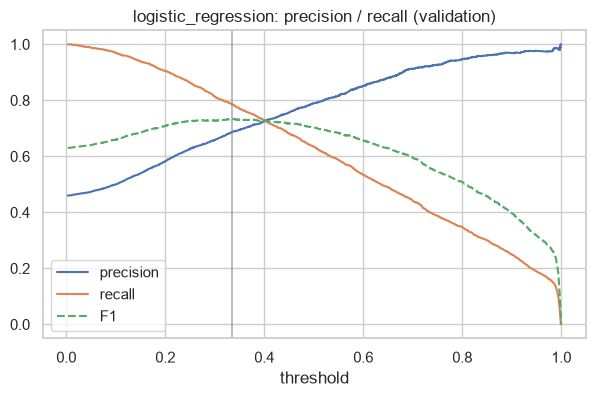

In [19]:
final_name = "logistic_regression"
model = best_models[final_name]
p_val = model.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, p_val)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_t = thresholds[np.argmax(f1[:-1])]
plt.figure(figsize=(7, 4))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.plot(thresholds, f1[:-1], label="F1", linestyle="--")
plt.axvline(best_t, color="gray", alpha=0.5)
plt.xlabel("threshold"); plt.legend(); plt.title(f"{final_name}: precision / recall (validation)")
print(f"model={final_name} | threshold maximizing F1 = {best_t:.2f}")

In [20]:
# Operational view: tutors can only call a fraction of students. How many at-risk students do we reach?
order = np.argsort(-p_val)
for share in [0.1, 0.2, 0.3, 0.5]:
    k = int(len(order) * share)
    caught = y_val[order[:k]].sum()
    print(f"contact top {share:.0%} ({k} students): precision={caught / k:.2f}, "
          f"recall={caught / y_val.sum():.2f}")

contact top 10% (621 students): precision=0.98, recall=0.21
contact top 20% (1243 students): precision=0.92, recall=0.40
contact top 30% (1865 students): precision=0.84, recall=0.55
contact top 50% (3108 students): precision=0.70, recall=0.76


### How early can we predict?

,cutoff_week,val_auc,at_risk_rate
0,1,0.709,0.473
1,2,0.726,0.453
2,4,0.789,0.442
3,6,0.809,0.431
4,8,0.826,0.420
5,10,0.846,0.410
6,12,0.852,0.402
7,16,0.886,0.383


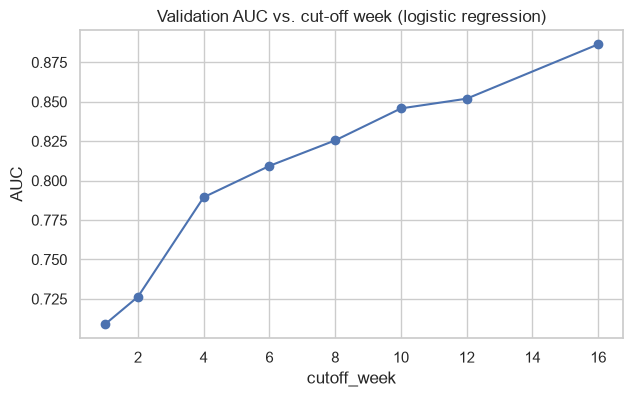

In [21]:
rows = []
for week in [1, 2, 4, 6, 8, 10, 12, 16]:
    rec, yy, mm = build_raw_records(students, assessments, submissions, cutoff_week=week)
    XX = np.array([compute_features(r) for r in rec], dtype=object)
    pp = mm.code_presentation.values
    m = best_models["logistic_regression"]
    m.fit(list(XX[np.isin(pp, ["2013B", "2013J"])]), yy[np.isin(pp, ["2013B", "2013J"])])
    rows.append((week, roc_auc_score(yy[pp == "2014B"], m.predict_proba(list(XX[pp == "2014B"]))[:, 1]),
                 yy.mean()))
early = pd.DataFrame(rows, columns=["cutoff_week", "val_auc", "at_risk_rate"])
ax = early.plot(x="cutoff_week", y="val_auc", marker="o", legend=False, figsize=(7, 4),
                title="Validation AUC vs. cut-off week (logistic regression)")
ax.set_ylabel("AUC")
early.round(3)

Even after 1-2 weeks the model is far better than random, and AUC keeps improving as more weeks (and the first
assessments) become available. Week 8 is a reasonable compromise: good accuracy while most of the course is still
ahead. (Notice the at-risk rate also drops with later cut-offs: students who already withdrew are excluded.)

## 6. Final model on the test presentation (2014J)

In [22]:
final = best_models[final_name]
final.fit(X_train + X_val, np.concatenate([y_train, y_val]))
p_test = final.predict_proba(X_test)[:, 1]
print(f"{final_name}: test AUC (2014J) = {roc_auc_score(y_test, p_test):.4f}")

logistic_regression: test AUC (2014J) = 0.8031


<Axes: title={'center': 'Top 15 features (logistic_regression)'}>

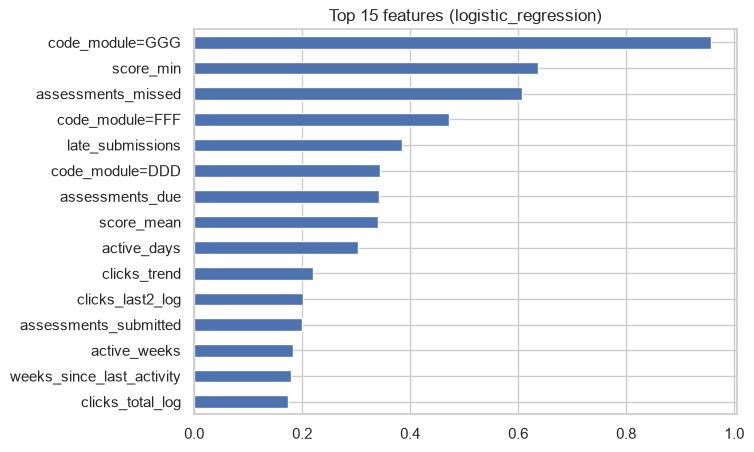

In [23]:
if final_name == "xgboost":
    booster = final[-1]
    imp = pd.Series(booster.feature_importances_, index=final[0].get_feature_names_out())
else:
    imp = pd.Series(np.abs(final[-1].coef_[0]), index=final[0].get_feature_names_out())
imp.sort_values().tail(15).plot.barh(figsize=(7, 5), title=f"Top 15 features ({final_name})")

**Conclusions**

- Behaviour in the first weeks (missed assessments, scores, recent VLE activity) predicts failure/withdrawal much
  better than demographics.
- On the future presentation (2014J) the AUC is 0.80, a bit lower than on validation (0.83): presentations
  differ (2014J has fewer at-risk students), which is exactly why the temporal split matters.
- Contacting the top 20-30% of students by predicted risk reaches a large share of those who will fail or withdraw,
  with high precision — a practical input for tutors.

Limitations: the data comes from one university (UK, distance learning, 2013-2014); the model should be
re-validated before using it elsewhere, and predictions must support tutors, not replace their judgment.